# SELECTING HUMAN TRANSCRIPTS (VERSION 4)
October 29, 2026

Here we explain our strategy in building the fourth version of the RiboFlow human transcriptome,
and we compare it with version 3.

v4 uses the [APPRIS](https://appris.bioinfo.cnio.es/) principal isoforms for GENCODE
[Release 50](https://www.gencodegenes.org/human/release_50.html). We pick one transcript per gene
in the same way as in v3: `MANE_Select` first, then the lowest PRINCIPAL level, then the longest.

New in v4 are three steps after the pick. They remove transcripts whose sequence is also in another
selected transcript, so their reads are no longer thrown away as multimappers:

1. Read-through genes (GENCODE tag `readthrough_gene`) are removed.
2. Transcripts that lie entirely inside a longer selected transcript are removed.
3. Bicistronic transcripts (identical exon structure, two genes) are collapsed to the gene with the
   longest CDS. Keeping both would put the same sequence in the reference twice.

The reasons and the mapping results are in `mapping_comparison_of_v3_and_v4.ipynb`. This notebook goes through
the selection step by step, like `v3/scripts/v3_appris_explore.ipynb`.

The steps are implemented in `generate_appris_reference.py`. We import that file and call its
functions instead of copying them here.

In [1]:
import sys, os, gzip, hashlib, tempfile
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from IPython.display import display_html, Markdown

sys.path.insert(0, "../../../..")   # repo root, for ref_lib
sys.path.insert(0, ".")             # scripts/, for the generator
import generate_appris_reference as gen
from ref_lib.Fasta import FastaFile

%matplotlib inline

Reference and annotation files:

In [2]:
transcripts_fasta = "../raw/sequence/gencode.v50.pc_transcripts.fa.gz"
gencode_gtf       = "../raw/annotation/gencode.v50.annotation.gtf.gz"
appris_file       = "../raw/annotation/appris_data.principal.txt"
v3_fasta          = "../../v3/riboflow_annot_and_ref/appris_human_v3_selected.fa.gz"
gtex_path         = "../../v3/raw/GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct.gz"

We read the GENCODE GTF into a dictionary with the exon and CDS coordinates of each transcript. This takes a minute or two:

In [3]:
gtf_all = gen.get_gtf_contents_genome(gencode_gtf)
gen.find_rel_utr_cds_positions(gtf_all)     # adds bed_CDS / bed_UTR_5 / bed_UTR_3 (transcript-relative, 0-based)
gtf_all["ENSG00000111640"]["ENST00000229239"]   # GAPDH

{'chrom': 'chr12',
 'exons': [(6534517, 6534569),
  (6534810, 6534861),
  (6536494, 6536593),
  (6536684, 6536790),
  (6536920, 6537010),
  (6537101, 6537216),
  (6537309, 6537390),
  (6537584, 6537996),
  (6538101, 6538371)],
 'CDS': [(6534833, 6534861, 1),
  (6536494, 6536593, 2),
  (6536684, 6536790, 3),
  (6536920, 6537010, 4),
  (6537101, 6537216, 5),
  (6537309, 6537390, 6),
  (6537584, 6537996, 7),
  (6538101, 6538167, 8)],
 'strand': '+',
 'start': 6534517,
 'end': 6538371,
 'gene_type': 'protein_coding',
 'length': 1285,
 'bed_CDS': (76, 1081),
 'bed_UTR_5': (0, 76),
 'bed_UTR_3': (1081, 1285)}

## Step 1. Selecting best APPRIS transcripts

We only use `PRINCIPAL` entries. If a gene has more than one, we pick in this order:
PRINCIPAL:1 + MANE_Select, PRINCIPAL:2 + MANE_Select, PRINCIPAL:1, PRINCIPAL:2, MANE_Select, longest
PRINCIPAL. Ties go to the longest transcript. This is the same rule as in v3.

In [4]:
appris_principal_transcripts, mane_select_transcripts = \
    gen.read_principal_appris_trascript_list(appris_file, gtf_all)
print("Genes with PRINCIPAL transcripts:", len(appris_principal_transcripts))
print("PRINCIPAL transcripts also flagged MANE_Select:", len(mane_select_transcripts))
best_appris_transcripts = gen.pick_best_appris_transcripts(appris_principal_transcripts, mane_select_transcripts)

Genes with PRINCIPAL transcripts: 20519
PRINCIPAL transcripts also flagged MANE_Select: 17579
  Picked by PRINCIPAL:1 + MANE_Select: 9982
  Picked by PRINCIPAL:2 + MANE_Select: 5505
  Picked by PRINCIPAL:1 only:           1529
  Picked by PRINCIPAL:2 only:           306
  Picked by MANE_Select:                2092
  Picked by longest PRINCIPAL:          1105
  Total picks: 20519


## Step 2. Protein-coding genes only

In [5]:
protein_coding_transcripts = gen.pick_protein_coding_transcripts(best_appris_transcripts)
print("protein_coding:", len(protein_coding_transcripts))

protein_coding: 20107


## Step 3. Remove read-through genes (new in v4)

A read-through gene is transcribed across two neighboring genes, so it shares exons with both. Reads
from the shared exons multimap and are discarded. We drop the read-through genes to remove this
duplicated sequence, which increases the mappability of the individual genes.

In [6]:
readthrough_gene_ids = gen.read_readthrough_gene_ids(gencode_gtf)
print("read-through genes in the GTF:", len(readthrough_gene_ids))
non_readthrough_transcripts = gen.remove_readthrough_genes(protein_coding_transcripts, readthrough_gene_ids)
print("remaining:", len(non_readthrough_transcripts))

read-through genes in the GTF: 665
  Removed 665 read-through genes.
remaining: 19442


## Step 4. Start and stop codons

We look at the codons at the CDS boundaries. Then we keep only transcripts whose start codon is at
most one mismatch away from ATG and whose stop codon is TAG, TAA or TGA.

In [7]:
def codon_table(transcript_dict):
    start, stop = defaultdict(int), defaultdict(int)
    for entry in FastaFile(transcripts_fasta):
        c = entry.header.strip().split("|")
        t, g = c[0].split(".")[0], c[1].split(".")[0]
        if "PAR_Y" in c[1] or t not in transcript_dict.get(g, {}):
            continue
        bed = transcript_dict[g][t].get("bed_CDS")
        if bed is None:
            continue
        start[entry.sequence[bed[0]:bed[0] + 3]] += 1
        stop_codon = entry.sequence[bed[1]:bed[1] + 3] or entry.sequence[bed[1] - 3:bed[1]]
        stop[stop_codon] += 1
    return (pd.Series(start).sort_values(ascending=False).rename("start"),
            pd.Series(stop).sort_values(ascending=False).rename("stop"))

start_before, stop_before = codon_table(non_readthrough_transcripts)
print("start codons before:", start_before.head(8).to_dict(), "... (", len(start_before), "distinct )")
print("stop codons before: ", stop_before.head(6).to_dict(), "... (", len(stop_before), "distinct )")

start codons before: {'ATG': 19390, 'CTG': 25, 'ATA': 6, 'ACG': 4, 'ATT': 4, 'GTG': 4, 'TTG': 2, 'GTA': 2} ... ( 13 distinct )
stop codons before:  {'TGA': 9529, 'TAA': 5518, 'TAG': 4368, 'AGA': 4, 'AGG': 2, 'ATA': 2} ... ( 23 distinct )


In [8]:
transcripts_with_proper_codons = gen.pick_transcripts_with_proper_codons(non_readthrough_transcripts, transcripts_fasta)
print("with proper start/stop codons:", len(transcripts_with_proper_codons))
start_after, stop_after = codon_table(transcripts_with_proper_codons)
print("start codons after:", start_after.to_dict())
print("stop codons after: ", stop_after.to_dict())

with proper start/stop codons: 19410


start codons after: {'ATG': 19367, 'CTG': 25, 'ACG': 4, 'GTG': 4, 'ATA': 3, 'ATT': 3, 'TTG': 2, 'ATC': 1, 'AAG': 1}
stop codons after:  {'TGA': 9527, 'TAA': 5517, 'TAG': 4366}


## Step 5. Remove fully contained transcripts (new in v4)

If all exonic bases of a transcript lie inside the exons of a longer selected transcript on the same
strand, it adds no new sequence. Its reads are always multimappers, so we drop it. Two transcripts of
equal length and identical sequence both survive this step. They are handled next.

In [9]:
after_containment = gen.remove_contained_transcripts(transcripts_with_proper_codons)
print("remaining:", len(after_containment))

  Removed 70 fully contained transcripts.
remaining: 19340


## Step 6. Collapse identical-sequence transcripts (new in v4)

Transcripts with the same chromosome, strand and exon intervals are bicistronic: two genes on one
RNA. We keep the one with the longest CDS. If we kept both, the same sequence would be in the
reference twice, and every read on it would be a multimapper.

In [10]:
groups_tsv = os.path.join(tempfile.mkdtemp(), "sequence_groups.tsv")
selected_transcripts = gen.collapse_identical_transcripts(after_containment, groups_tsv)
print("selected:", len(selected_transcripts))
pd.read_csv(groups_tsv, sep="\t")

  4 identical-sequence groups; removed 4 shorter-CDS members (see /var/folders/ry/4dz4gjf1627b9m_r_qwgz2ym0000gn/T/tmp2_bpwfpr/sequence_groups.tsv).
selected: 19336


,group_id,member_tx,member_gene,region,representative
0,shared_PYURF_PIGY,ENST00000273968,PYURF,UTR5:1-76|CDS:77-418|UTR3:419-1311,True
1,shared_PYURF_PIGY,ENST00000527353,PIGY,UTR5:1-519|CDS:520-732|UTR3:733-1311,False
2,shared_SLC35A4_ENSG00000293600,ENST00000323146,SLC35A4,UTR5:1-735|CDS:736-1707|UTR3:1708-2666,True
3,shared_SLC35A4_ENSG00000293600,ENST00000715679,ENSG00000293600,UTR5:1-16|CDS:17-325|UTR3:326-2666,False
4,shared_FAM220A_SMIM10L3,ENST00000313324,FAM220A,UTR5:1-476|CDS:477-1253|UTR3:1254-2220,True
5,shared_FAM220A_SMIM10L3,ENST00000578372,SMIM10L3,UTR5:1-209|CDS:210-413|UTR3:414-2220,False
6,shared_GDF1_CERS1,ENST00000247005,GDF1,UTR5:1-1408|CDS:1409-2524|UTR3:2525-2579,True
7,shared_GDF1_CERS1,ENST00000623882,CERS1,UTR5:1-86|CDS:87-1136|UTR3:1137-2579,False


## Are CDS lengths divisible by 3?

In [11]:
CDS_remainder_by_3 = [0, 0, 0]
cds_violators = []
for g, transcripts in selected_transcripts.items():
    for t, c in transcripts.items():
        r = (c["bed_CDS"][1] - c["bed_CDS"][0]) % 3
        CDS_remainder_by_3[r] += 1
        if r:
            cds_violators.append(t)
print("CDS length divisible by 3:    ", CDS_remainder_by_3[0])
print("CDS length NOT divisible by 3:", len(cds_violators), cds_violators[:10])

CDS length divisible by 3:     19323
CDS length NOT divisible by 3: 13 ['ENST00000649616', 'ENST00000504970', 'ENST00000429239', 'ENST00000394191', 'ENST00000432841', 'ENST00000424348', 'ENST00000445557', 'ENST00000440231', 'ENST00000435756', 'ENST00000412796']


## Length distributions

missing 5' UTR: 452   missing 3' UTR: 11
CDS length: median 1284, mean 1725


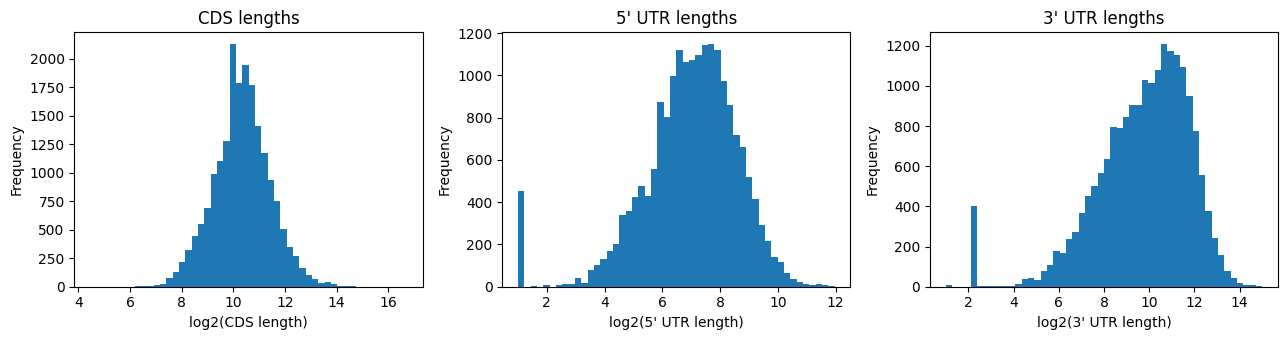

In [12]:
utr5_lengths, utr3_lengths, cds_lengths = [], [], []
missing_utr5 = missing_utr3 = 0
for g, transcripts in selected_transcripts.items():
    c = next(iter(transcripts.values()))
    u5, u3 = c.get("bed_UTR_5"), c.get("bed_UTR_3")
    missing_utr5 += u5 is None
    missing_utr3 += u3 is None
    utr5_lengths.append(u5[1] - u5[0] if u5 else 0)
    utr3_lengths.append(u3[1] - u3[0] if u3 else 0)
    cds_lengths.append(c["bed_CDS"][1] - c["bed_CDS"][0])
median_cds_length, mean_cds_length = int(np.median(cds_lengths)), int(np.mean(cds_lengths))
print(f"missing 5' UTR: {missing_utr5}   missing 3' UTR: {missing_utr3}")
print(f"CDS length: median {median_cds_length}, mean {mean_cds_length}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (vals, label) in zip(axes, ((cds_lengths, "CDS"), (utr5_lengths, "5' UTR"), (utr3_lengths, "3' UTR"))):
    ax.hist(np.log2(np.array(vals) + 2), bins=50)
    ax.set_xlabel(f"log2({label} length)"); ax.set_ylabel("Frequency"); ax.set_title(f"{label} lengths")
plt.tight_layout()

## Summary

In [ ]:
print(f"CDS length divisible by 3: {CDS_remainder_by_3[0]}, not: {len(cds_violators)}")
print(f"start with ATG: {start_after.get('ATG', 0)}")
print(f"CDS length: median {median_cds_length} nt, mean {mean_cds_length} nt")
print(f"no 5' UTR: {missing_utr5}   no 3' UTR: {missing_utr3}")
print("Y-chromosome PAR copies (PAR_Y in the gene ID) are skipped when the FASTA is written.")

steps = {
    "genes with a PRINCIPAL isoform":     appris_principal_transcripts,
    "protein-coding":                     protein_coding_transcripts,
    "after read-through removal":         non_readthrough_transcripts,
    "with proper start/stop codons":      transcripts_with_proper_codons,
    "after containment removal":          after_containment,
    "after identical-sequence collapse":  selected_transcripts,
}
summary = pd.DataFrame({"transcripts": {k: len(v) for k, v in steps.items()}})
summary["removed"] = -summary.transcripts.diff().fillna(0).astype(int)
summary

## Files and hash sums

APPRIS principal isoforms for GENCODE Release 50 (GRCh38.p14), downloaded from
https://appris.bioinfo.cnio.es/#/downloads. GENCODE files are from https://www.gencodegenes.org/human/.

In [14]:
for p in (transcripts_fasta, gencode_gtf, appris_file):
    opener = gzip.open if p.endswith(".gz") else open
    with opener(p, "rb") as fh:
        print(hashlib.md5(fh.read()).hexdigest(), " ", os.path.basename(p))

b5f918462f7793281b7ee9a26e0925a3   gencode.v50.pc_transcripts.fa.gz


70146f2bab01d3f39b2ac9b3f172842c   gencode.v50.annotation.gtf.gz
1a4873375d5d24f465708a30aa921a38   appris_data.principal.txt


## Generating the RiboFlow reference and annotation

`generate_riboflow_ref_and_annot.sh` in this folder runs `generate_appris_reference.py` and builds
the Bowtie2 index in `../riboflow_annot_and_ref/`.

## Comparison with the previous RiboFlow reference version

**Convention:**
*v3* is the previous reference (GENCODE v48).
*v4* is the current reference (GENCODE v50).

We compare the genes in v4 to those in v3 by Ensembl gene ID.

v3 19871   v4 19336   shared 19331
only v3 540   only v4 5


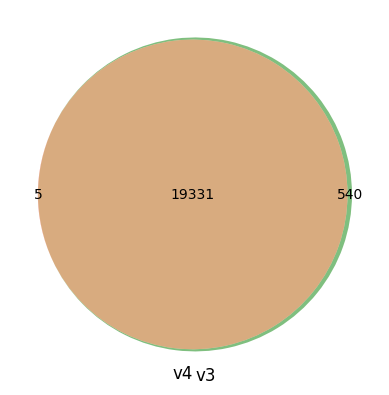

In [15]:
prev_gene_ids, prev_gene_names = [], {}
for f in FastaFile(v3_fasta):
    c = f.header.split("|")
    prev_gene_ids.append(c[1].split(".")[0]); prev_gene_names[c[1].split(".")[0]] = c[5]
previous_gene_set = set(prev_gene_ids)
current_gene_set  = set(selected_transcripts)
current_minus_prev_genes = current_gene_set - previous_gene_set
prev_minus_current_genes = previous_gene_set - current_gene_set
print(f"v3 {len(previous_gene_set)}   v4 {len(current_gene_set)}   shared {len(current_gene_set & previous_gene_set)}")
print(f"only v3 {len(prev_minus_current_genes)}   only v4 {len(current_minus_prev_genes)}")
venn2([current_gene_set, previous_gene_set], set_labels=("v4", "v3"), alpha=0.5);

### Transcript-level differences

For a gene in both references, the transcript can be the same, the same with a new ENST version
number (GENCODE v48 to v50), or a different isoform. The selection rule did not change, so a different
isoform means the APPRIS or MANE annotation changed.

In [16]:
v4_fasta = "../riboflow_annot_and_ref/appris_human_v4_selected.fa.gz"
def gene_to_tx(path):
    return {f.header.split("|")[1].split(".")[0]: f.header.split("|")[0] for f in FastaFile(path)}
tx3, tx4 = gene_to_tx(v3_fasta), gene_to_tx(v4_fasta)
shared = sorted(set(tx3) & set(tx4))
same     = [g for g in shared if tx3[g] == tx4[g]]
reversed_ = [g for g in shared if tx3[g] != tx4[g] and tx3[g].split(".")[0] == tx4[g].split(".")[0]]
swapped  = [g for g in shared if tx3[g].split(".")[0] != tx4[g].split(".")[0]]
Markdown(f"""
| | genes |
|---|---|
| in both v3 and v4 | {len(shared)} |
| &nbsp;&nbsp; identical transcript, same version | {len(same)} |
| &nbsp;&nbsp; same transcript, ENST version bumped (v48 → v50) | {len(reversed_)} |
| &nbsp;&nbsp; different isoform picked | {len(swapped)} |
| only in v3 (dropped) | {len(set(tx3) - set(tx4))} |
| only in v4 (gained) | {len(set(tx4) - set(tx3))} |
""")


| | genes |
|---|---|
| in both v3 and v4 | 19331 |
| &nbsp;&nbsp; identical transcript, same version | 17829 |
| &nbsp;&nbsp; same transcript, ENST version bumped (v48 → v50) | 815 |
| &nbsp;&nbsp; different isoform picked | 687 |
| only in v3 (dropped) | 540 |
| only in v4 (gained) | 5 |


### What are the genes missing from v4?

Most of the loss is on purpose: the three new steps remove genes. We label each v3-only gene with the
first reason that applies, in pipeline order.

In [17]:
def classify_lost(g):
    if g not in gtf_all:                                     return "gene ID retired in GENCODE v50"
    if g not in appris_principal_transcripts:               return "no PRINCIPAL isoform in APPRIS (v50)"
    if g not in protein_coding_transcripts:                 return "not protein_coding in v50"
    if g in readthrough_gene_ids:                           return "read-through gene removed (Step 3)"
    if g not in transcripts_with_proper_codons:             return "improper start/stop codon (Step 4)"
    if g not in after_containment:                          return "contained transcript removed (Step 5)"
    if g not in selected_transcripts:                       return "bicistronic member dropped (Step 6)"
    return "other"
lost = pd.DataFrame({"gene": [prev_gene_names[g] for g in prev_minus_current_genes],
                     "reason": [classify_lost(g) for g in prev_minus_current_genes]}, index=sorted(prev_minus_current_genes))
lost.reason.value_counts()

reason
read-through gene removed (Step 3)       468
contained transcript removed (Step 5)     66
bicistronic member dropped (Step 6)        4
no PRINCIPAL isoform in APPRIS (v50)       1
gene ID retired in GENCODE v50             1
Name: count, dtype: int64

The genes removed by Steps 3, 5 and 6 are described in `mapping_comparison_of_v3_and_v4.ipynb`. For the rest we look
at GTEx expression, as in the v3 notebook.

In [18]:
gtex_tpm = pd.read_csv(gtex_path, sep="\t", header=0, index_col=0, skiprows=2)
gtex_tpm.index = [x.split(".")[0] for x in gtex_tpm.index]

def gtex_summary(gene_ids):
    sub = gtex_tpm.loc[[g for g in gtex_tpm.index if g in gene_ids]]
    tpm = sub.iloc[:, 1:]
    out = pd.DataFrame({"gene": sub.iloc[:, 0], "Median TPM": tpm.median(axis=1), "Min TPM": tpm.min(axis=1),
                        "Max TPM": tpm.max(axis=1), "Max Tis.": tpm.idxmax(axis=1)})
    return out.sort_values("Median TPM", ascending=False)

unexplained = lost[~lost.reason.str.contains("Step")]
print(f"{len(unexplained)} v3 genes lost for reasons other than Steps 3/5/6; {unexplained.index.isin(gtex_tpm.index).sum()} of them in GTEx")
unexplained.join(gtex_summary(set(unexplained.index)).drop(columns="gene"), how="left")

2 v3 genes lost for reasons other than Steps 3/5/6; 1 of them in GTEx


,gene,reason,Median TPM,Min TPM,Max TPM,Max Tis.
ENSG00000203546,NAT8B,no PRINCIPAL isoform in APPRIS (v50),2.57526,0.238461,6.9595,Nerve_Tibial
ENSG00000282034,MATR3,gene ID retired in GENCODE v50,NaN,NaN,NaN,NaN


v3 has 19871 genes and v4 has 19336. 19331 are in both.

Of the 540 genes only in v3, 538 are removed on purpose: 468 read-through genes (Step 3), 66 contained
transcripts (Step 5) and 4 bicistronic members (Step 6). The other two are annotation changes between
GENCODE v48 and v50. Neither is in GTEx.

**MATR3 (ENSG00000267360):** a second gene ID for MATR3 in v48. It was retired in v50. MATR3 is still in
v4 under ENSG00000015479. It is also the biggest gainer of CDS reads in the mapping comparison, because
in v3 its reads multimapped between the two copies.

**NAT8B (ENSG00000273155):** has no PRINCIPAL isoform in the v50 APPRIS list.

In v2 to v3 the lost genes were mostly low-expression pseudogenes and lncRNAs. In v3 to v4 almost
nothing is lost by annotation changes. The difference is the removal of duplicated sequence.

### Newly added genes

Genes in v4 that were not in v3, with their GTEx expression.

In [19]:
gtex_added = gtex_summary(current_minus_prev_genes)
display_html(f"<center><b>Genes in v4 − v3</b><br>{len(current_minus_prev_genes)} genes, {len(gtex_added)} in GTEx</center>", raw=True)
gtex_added.head(25)

Genes in v4 − v3 5 genes, 4 in GTEx

,gene,Median TPM,Min TPM,Max TPM,Max Tis.
ENSG00000293488,ENSG00000293488,0.091446,0.0,21.806500,Cells_EBV-transformed_lymphocytes
ENSG00000225997,OR4A8,0.000000,0.0,0.000000,Adipose_Subcutaneous
ENSG00000272987,OR5AL1,0.000000,0.0,0.000000,Adipose_Subcutaneous
ENSG00000262085,OR1P1,0.000000,0.0,0.050765,Testis


In [20]:
v48_appris = pd.read_csv("../../v3/raw/annotation/appris_data.principal.txt", sep="\t")
v48_status = v48_appris.groupby("Gene ID")["APPRIS Annotation"].apply(lambda s: ",".join(sorted(set(s))))
added = pd.DataFrame({"gene": [next(iter(selected_transcripts[g].values())).get("gene_name", g) for g in sorted(current_minus_prev_genes)],
                      "v48 APPRIS": [v48_status.get(g, "absent") for g in sorted(current_minus_prev_genes)]},
                     index=sorted(current_minus_prev_genes))
added.join(gtex_added.drop(columns="gene"), how="left")

,gene,v48 APPRIS,Median TPM,Min TPM,Max TPM,Max Tis.
ENSG00000225997,OR4A8,PRINCIPAL:1,0.000000,0.0,0.000000,Adipose_Subcutaneous
ENSG00000254104,ENSG00000254104,absent,NaN,NaN,NaN,NaN
ENSG00000262085,OR1P1,PRINCIPAL:1,0.000000,0.0,0.050765,Testis
ENSG00000272987,OR5AL1,PRINCIPAL:1,0.000000,0.0,0.000000,Adipose_Subcutaneous
ENSG00000293488,CLECL1,absent,0.091446,0.0,21.806500,Cells_EBV-transformed_lymphocytes


Only 5 genes are new in v4. All have very low GTEx expression.

* **OR4A8, OR5AL1, OR1P1:** olfactory receptors. They were PRINCIPAL:1 in v48 too, but their v48 CDS
  ended without a stop codon (AAT, AAA, GAC), so they failed the stop codon check in v3. In v50 the CDS
  ends in a stop codon (TAA, TAA, TGA). TPM is zero or near zero in every tissue. The CDS of OR5AL1 is
  still not a multiple of 3.
* **CLECL1 (ENSG00000293488):** lncRNA in v48, protein coding with a MANE_Select PRINCIPAL:2 isoform in
  v50. Median TPM 0.09, highest in EBV-transformed lymphocytes.
* **ENSG00000254104:** processed pseudogene in v48, protein coding with a PRINCIPAL:1 isoform in v50.
  Not in GTEx.

So v3 to v4 is almost only removals: 540 genes dropped, 5 gained. The selection rule did not change.